In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (768, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nOutcome Distribution:")
print(df["Outcome"].value_counts())

Missing Values:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

Duplicate Records: 0

Outcome Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


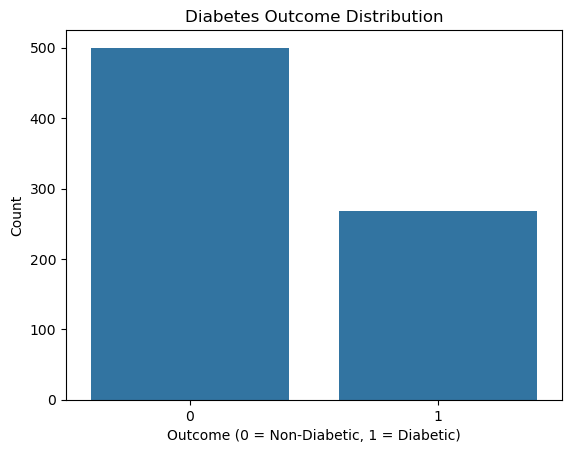

In [5]:
sns.countplot(x="Outcome", data=df)
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = Non-Diabetic, 1 = Diabetic)")
plt.ylabel("Count")
plt.show()

In [6]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  
0     0.627   50  
1     0.351   31  
2     0.672   32  
3     0.167   21  
4     2.288   33  

Target:
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (614, 8)
Testing Data: (154, 8)


In [8]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [9]:
model = KNeighborsClassifier(n_neighbors=5)

model.fit(X_train, y_train)

KNeighborsClassifier()

In [10]:
y_pred = model.predict(X_test)

print("Predicted Values:")
print(y_pred[:20])

print("\nActual Values:")
print(y_test.iloc[:20].values)

Predicted Values:
[1 0 0 0 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]

Actual Values:
[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0]


In [11]:
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy

print("Accuracy:", accuracy * 100, "%")
print("Error Rate:", error_rate * 100, "%")

Accuracy: 70.12987012987013 %
Error Rate: 29.87012987012987 %


In [12]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)

Precision: 0.5833333333333334
Recall: 0.5185185185185185


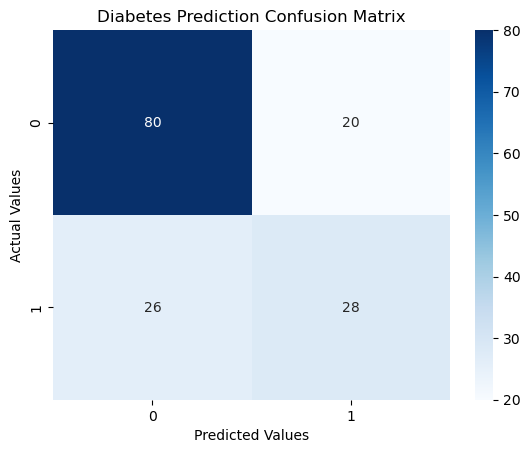

In [13]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Diabetes Prediction Confusion Matrix")
plt.show()

In [14]:
print("Diabetes Prediction using KNN")
print("-----------------------------")
print("Accuracy:", accuracy * 100, "%")
print("Error Rate:", error_rate * 100, "%")
print("Precision:", precision)
print("Recall:", recall)
print("\nConfusion Matrix:")
print(cm)

Diabetes Prediction using KNN
-----------------------------
Accuracy: 70.12987012987013 %
Error Rate: 29.87012987012987 %
Precision: 0.5833333333333334
Recall: 0.5185185185185185

Confusion Matrix:
[[80 20]
 [26 28]]


In [15]:

# PRACTICAL 4: DIABETES PREDICTION USING K-NEAREST NEIGHBOURS (KNN)
#
# 1. INTRODUCTION
#
# Diabetes is a chronic disease that occurs when the body cannot
# properly regulate blood glucose levels.
#
# Machine Learning can be used to analyze medical data and predict
# whether a person is likely to have diabetes.
#
# In this practical, the K-Nearest Neighbours (KNN) algorithm is
# used to predict diabetes using the diabetes.csv dataset.
#
# This is a supervised machine learning problem because the dataset
# contains input features as well as a known target variable.
#
# The task is a binary classification problem:
# - 0: Person does not have diabetes.
# - 1: Person has diabetes.
#
# 2. DATASET DESCRIPTION
#
# The dataset used is diabetes.csv.
#
# It contains 768 records and 9 columns.
#
# The eight input features are:
#
# 1. Pregnancies:
#    Number of times the patient has been pregnant.
#
# 2. Glucose:
#    Plasma glucose concentration.
#
# 3. BloodPressure:
#    Diastolic blood pressure.
#
# 4. SkinThickness:
#    Thickness of the skin fold.
#
# 5. Insulin:
#    Two-hour serum insulin level.
#
# 6. BMI:
#    Body Mass Index.
#
# 7. DiabetesPedigreeFunction:
#    Indicates the genetic influence or family history of diabetes.
#
# 8. Age:
#    Age of the patient.
#
# Target variable:
# - Outcome: 0 means non-diabetic and 1 means diabetic.
#
# 3. DATA PREPROCESSING
#
# Data preprocessing is performed to prepare the dataset for
# machine learning.
#
# The dataset is loaded using Pandas.
#
# The target variable Outcome is separated from the input features.
#
# X contains the eight independent features.
# y contains the Outcome column.
#
# The dataset is divided into training and testing sets using
# train_test_split().
#
# 80% of the data is used for training and 20% for testing.
#
# Stratified splitting is used to maintain approximately the
# same proportion of both target classes in the training and
# testing datasets.
#
# 4. FEATURE SCALING USING STANDARD SCALER
#
# KNN is a distance-based algorithm. Therefore, features with
# larger numerical ranges can dominate distance calculations.
#
# StandardScaler is used to standardize the input features.
#
# It transforms the features so that they have approximately
# zero mean and unit standard deviation.
#
# Formula:
#
#       Z = (X - Mean) / Standard Deviation
#
# Where:
# X                  = Original feature value
# Mean               = Mean of the feature
# Standard Deviation = Standard deviation of the feature
# Z                  = Standardized feature value
#
# The scaler is fitted only on the training data and then used
# to transform both training and testing data.
#
# This prevents information from the test dataset from influencing
# the scaling parameters used during training.
#
# 5. K-NEAREST NEIGHBOURS (KNN) ALGORITHM
#
# K-Nearest Neighbours is a supervised machine learning algorithm
# used for classification and regression.
#
# It is a non-parametric and instance-based learning algorithm.
#
# KNN does not build an explicit mathematical model during training.
# Instead, it stores the training data and uses it to classify
# new observations.
#
# WORKING OF KNN:
#
# Step 1: Select the value of K, representing the number of
#         nearest neighbours to consider.
#
# Step 2: Calculate the distance between the new data point
#         and all training data points.
#
# Step 3: Identify the K nearest neighbours.
#
# Step 4: Count the class labels of these neighbours.
#
# Step 5: Assign the majority class to the new data point.
#
# In this practical, K = 5 is used.
#
# Therefore, the algorithm considers the five nearest training
# samples and predicts the class using majority voting.
#
# 6. EUCLIDEAN DISTANCE
#
# Euclidean distance is commonly used in KNN to calculate the
# distance between two data points.
#
# Formula:
#
#       d = sqrt((x1-y1)^2 + (x2-y2)^2 + ... + (xn-yn)^2)
#
# Where:
# x and y are two data points.
# n is the number of features.
# d is the calculated distance.
#
# A smaller distance indicates that two data points are more
# similar to each other.
#
# Since KNN depends on distance calculations, feature scaling
# is important for obtaining reliable predictions.
#
# 7. MODEL TRAINING AND PREDICTION
#
# The KNeighborsClassifier class from Scikit-learn is used
# to implement the KNN algorithm.
#
# The model is initialized with:
#
#       n_neighbors = 5
#
# The fit() method is used to train the classifier using
# the scaled training data.
#
# The predict() method is used to predict the Outcome values
# for the testing data.
#
# The predicted values are compared with the actual values
# to evaluate the model's performance.
#
# 8. MODEL EVALUATION
#
# Different evaluation metrics are used to measure the
# performance of the classification model.
#
# A. CONFUSION MATRIX
#
# A confusion matrix is used to compare actual and predicted
# class labels.
#
# It contains four values:
#
# 1. True Positive (TP):
#    Patient has diabetes and the model correctly predicts 1.
#
# 2. True Negative (TN):
#    Patient does not have diabetes and the model correctly
#    predicts 0.
#
# 3. False Positive (FP):
#    Patient does not have diabetes, but the model predicts 1.
#
# 4. False Negative (FN):
#    Patient has diabetes, but the model predicts 0.
#
# B. ACCURACY
#
# Accuracy measures the proportion of correctly classified
# observations out of all observations.
#
# Formula:
#
#       Accuracy = (TP + TN) / (TP + TN + FP + FN)
#
# C. ERROR RATE
#
# Error rate measures the proportion of incorrect predictions.
#
# Formula:
#
#       Error Rate = (FP + FN) / Total Observations
#
#       Error Rate = 1 - Accuracy
#
# D. PRECISION
#
# Precision measures how many observations predicted as positive
# are actually positive.
#
# Formula:
#
#       Precision = TP / (TP + FP)
#
# Higher precision means fewer false positive predictions.
#
# E. RECALL
#
# Recall measures how many actual positive observations are
# correctly identified by the model.
#
# Formula:
#
#       Recall = TP / (TP + FN)
#
# Higher recall means fewer actual diabetic patients are missed.
#
# 9. VISUALIZATION
#
# The confusion matrix is displayed using a heatmap.
#
# A heatmap represents the values of the confusion matrix
# using different colour intensities.
#
# It makes it easier to identify correct and incorrect
# predictions made by the classifier.
#
# 10. ADVANTAGES OF KNN
#
# 1. Simple and easy to implement.
# 2. No complex training process is required.
# 3. Can be used for both classification and regression.
# 4. Can handle multi-class classification problems.
# 5. Makes predictions based on similarities between data points.
#
# 11. LIMITATIONS OF KNN
#
# 1. Prediction can be slow for large datasets because distances
#    must be calculated against training samples.
# 2. Sensitive to feature scaling.
# 3. Performance depends on the selected value of K.
# 4. Can be affected by noisy data and irrelevant features.
# 5. Performance may decrease when the number of features is high.
#
# DATASET LIMITATION:
#
# Some measurements such as Glucose, BloodPressure, SkinThickness,
# Insulin and BMI contain zero values that may represent missing
# or invalid measurements.
#
# In the current implementation, these values are not replaced
# or imputed. This can affect prediction quality.
#
# 12. CONCLUSION
#
# In this practical, diabetes prediction is performed using the
# K-Nearest Neighbours classification algorithm.
#
# The diabetes.csv dataset is divided into training and testing
# sets using an 80:20 ratio.
#
# StandardScaler is applied to standardize the input features.
# A KNN classifier with K = 5 is trained to predict whether
# a patient has diabetes.
#
# Finally, the model is evaluated using accuracy, error rate,
# precision, recall and a confusion matrix.
#
# The practical demonstrates how machine learning classification
# techniques can be applied to medical data for prediction.
